Step 1: Loading Iris dataset...
Dataset loaded successfully!
Features: (150, 4)
Labels: (150,)

Step 2: Splitting dataset...
Training samples: 105
Testing samples: 45

Step 3: Standardizing features...
Feature scaling completed!

Step 4: Defining hyperparameters...

Step 5: Starting Grid Search with 5-fold CV...
Grid Search completed!
Best parameters: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Best CV accuracy: 0.981

Step 6: Evaluating the best model...
Test accuracy: 0.9111

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45


Step 7: Displaying confusion matrix...


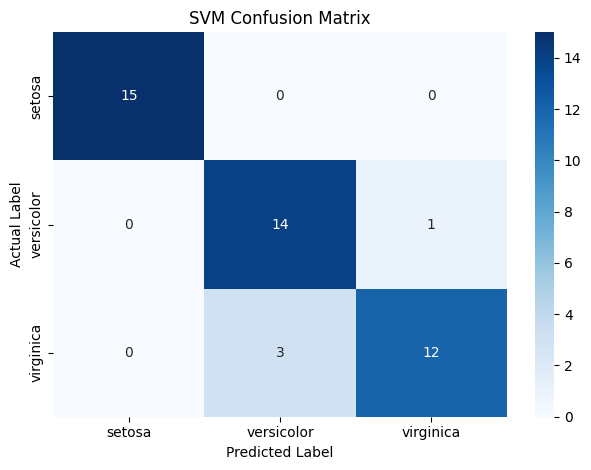


Step 8: Showing top 5 Grid Search results...
    param_C  param_gamma param_kernel  mean_test_score  rank_test_score
10      1.0        0.100          rbf         0.980952                1
27    100.0        0.100       linear         0.980952                1
31    100.0        0.001       linear         0.980952                1
29    100.0        0.010       linear         0.980952                1
25    100.0        1.000       linear         0.980952                1

Step 9: Starting 5-fold cross-validation...
Scores for each fold: [1.         0.95238095 0.95238095 0.95238095 1.        ]
Mean accuracy: 0.9714
Standard deviation: 0.0233

Step 10: Plotting cross-validation results...


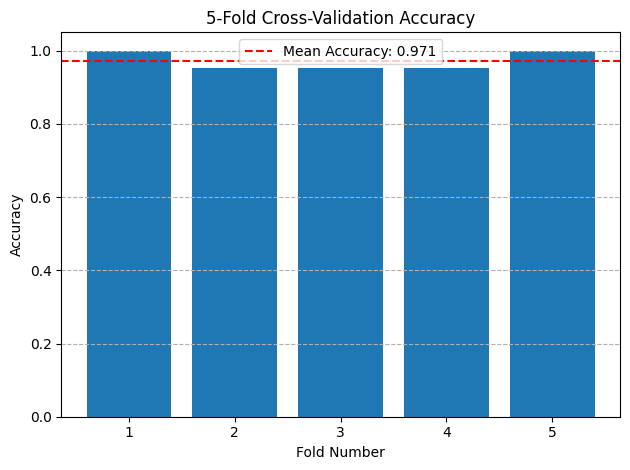


Experiment completed successfully!
Grid Search finds the best hyperparameters.
Cross-validation evaluates model consistency.


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load Dataset
print("Step 1: Loading Iris dataset...")
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Labels:", y.shape)

# 2. Split Dataset
print("\nStep 2: Splitting dataset...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 3. Feature Scaling
print("\nStep 3: Standardizing features...")
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Feature scaling completed!")

# 4. Hyperparameter Tuning
print("\nStep 4: Defining hyperparameters...")
params = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

# 5. Grid Search
print("\nStep 5: Starting Grid Search with 5-fold CV...")
grid = GridSearchCV(
    SVC(), params, cv=5, scoring='accuracy', n_jobs=-1
)
grid.fit(X_train, y_train)
print("Grid Search completed!")

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

# 6. Test the Best Model
print("\nStep 6: Evaluating the best model...")
model = grid.best_estimator_
y_pred = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# 7. Confusion Matrix
print("\nStep 7: Displaying confusion matrix...")
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 8. Display Top Grid Search Results
print("\nStep 8: Showing top 5 Grid Search results...")
results = pd.DataFrame(grid.cv_results_)

print(
    results[
        ['param_C', 'param_gamma', 'param_kernel',
         'mean_test_score', 'rank_test_score']
    ].sort_values('rank_test_score').head()
)

# 9. K-Fold Cross-Validation
print("\nStep 9: Starting 5-fold cross-validation...")
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    SVC(), X_train, y_train, cv=kf, scoring='accuracy'
)

print("Scores for each fold:", cv_scores)
print("Mean accuracy:", round(np.mean(cv_scores), 4))
print("Standard deviation:", round(np.std(cv_scores), 4))

# 10. Plot Cross-Validation Scores
print("\nStep 10: Plotting cross-validation results...")

plt.bar(range(1, k + 1), cv_scores)
plt.axhline(
    np.mean(cv_scores), color='red', linestyle='--',
    label=f'Mean Accuracy: {np.mean(cv_scores):.3f}'
)

plt.title("5-Fold Cross-Validation Accuracy")
plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

# 11. Conclusion
print("\nExperiment completed successfully!")
print("Grid Search finds the best hyperparameters.")
print("Cross-validation evaluates model consistency.")